2026297, Erick Henrique da Silva,

PREDICTING PREMIER LEAGUE MATCHES OUTCOMES

Github Link: https://github.com/2026297-cyber/Machine-Learning

Datasets: https://datahub.io/football/english-premier-league

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree      
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV    
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics                                      
from sklearn import tree
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report


import warnings
warnings.filterwarnings('ignore')

In [2]:
df1  = pd.read_csv("season-2526.csv")
df2  = pd.read_csv("season-2425.csv")
df3  = pd.read_csv("season-2324.csv")
df4  = pd.read_csv("season-2223.csv")
df5  = pd.read_csv("season-2122.csv")
df6  = pd.read_csv("season-2021.csv")
df7  = pd.read_csv("season-1920.csv")
df8  = pd.read_csv("season-1819.csv")
df9  = pd.read_csv("season-1718.csv")
df10 = pd.read_csv("season-1617.csv")

df = pd.concat([df1, df2, df3, df4, df5, df6, df7, df8, df9, df10])

DICTIONARY
- FTHG = Full Time Home Goals 
- FTAG = Full Time Away Goals 
- FTR  = Full Time Result - (Home = H, Away = A, Draw = D) - TARGET
- HTHG = Half Time Home Goals 
- HTAG = Half Time Away Goals 
- HTR  = Half Time Result 
- Referee = Match Referee
- HS   = Home Shots 
- AS   = Away Shots 
- HST  = Home Shots on Target 
- AST  = Away Shots on Target 
- HF   = Home Fouls 
- AF   = Away Fouls 
- HC   = Home Corners 
- AC   = Away Corners 
- HY   = Home Yellows 
- AY   = Away Yellows 
- HR   = Home Reds 
- AR   = Away Reds

This Dataset is the result of the last 10 Premier League seasons from 2016/17 to 2025/26. Each dataset has 380 rows and 22 columns, for a total 3800 rows. The model seeks to predict the match results using the statistics of these matches as shots, cornes and fouls.

Question: Which features most affect the results of a match?


In [3]:
df

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,2025-08-15,Liverpool,Bournemouth,4,2,H,1,0,H,A Taylor,...,10,3,7,10,6,7,1,2,0,0
1,2025-08-16,Aston Villa,Newcastle,0,0,D,0,0,D,C Pawson,...,3,3,13,11,3,6,1,1,1,0
2,2025-08-16,Brighton,Fulham,1,1,D,0,0,D,S Barrott,...,4,2,16,15,4,3,3,3,0,0
3,2025-08-16,Sunderland,West Ham,3,0,H,0,0,D,R Jones,...,5,4,8,10,5,7,0,1,0,0
4,2025-08-16,Tottenham,Burnley,3,0,H,1,0,H,M Oliver,...,6,4,14,8,6,5,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375,2017-05-21,Liverpool,Middlesbrough,3,0,H,1,0,H,M Atkinson,...,10,3,13,8,3,3,0,1,0,0
376,2017-05-21,Man United,Crystal Palace,2,0,H,2,0,H,A Taylor,...,2,1,16,10,3,6,2,0,0,0
377,2017-05-21,Southampton,Stoke,0,1,A,0,0,D,L Probert,...,6,3,12,10,4,10,2,4,0,0
378,2017-05-21,Swansea,West Brom,2,1,H,0,1,A,M Dean,...,2,5,8,10,7,4,1,1,0,0


In [4]:
df.shape

(3800, 22)

In [5]:
df.describe()

,FTHG,FTAG,HTHG,HTAG,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
count,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000
mean,1.555263,1.279737,0.697895,0.564211,13.867105,11.480263,4.768158,4.023421,10.598158,10.868158,5.664474,4.687632,1.656579,1.850000,0.053947,0.061053
std,1.313304,1.207771,0.847582,0.780172,5.685582,5.060168,2.618839,2.362564,3.426335,3.562880,3.060554,2.796334,1.271598,1.311911,0.236196,0.244893
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000,10.000000,8.000000,3.000000,2.000000,8.000000,8.000000,3.000000,3.000000,1.000000,1.000000,0.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000,13.000000,11.000000,4.000000,4.000000,10.000000,11.000000,5.000000,4.000000,2.000000,2.000000,0.000000,0.000000
75%,2.000000,2.000000,1.000000,1.000000,17.000000,15.000000,6.000000,5.000000,13.000000,13.000000,8.000000,6.000000,2.000000,3.000000,0.000000,0.000000
max,9.000000,9.000000,5.000000,5.000000,37.000000,37.000000,17.000000,15.000000,24.000000,26.000000,19.000000,19.000000,7.000000,8.000000,2.000000,2.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 3800 entries, 0 to 379
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      3800 non-null   str  
 1   HomeTeam  3800 non-null   str  
 2   AwayTeam  3800 non-null   str  
 3   FTHG      3800 non-null   int64
 4   FTAG      3800 non-null   int64
 5   FTR       3800 non-null   str  
 6   HTHG      3800 non-null   int64
 7   HTAG      3800 non-null   int64
 8   HTR       3800 non-null   str  
 9   Referee   3800 non-null   str  
 10  HS        3800 non-null   int64
 11  AS        3800 non-null   int64
 12  HST       3800 non-null   int64
 13  AST       3800 non-null   int64
 14  HF        3800 non-null   int64
 15  AF        3800 non-null   int64
 16  HC        3800 non-null   int64
 17  AC        3800 non-null   int64
 18  HY        3800 non-null   int64
 19  AY        3800 non-null   int64
 20  HR        3800 non-null   int64
 21  AR        3800 non-null   int64
dtypes: int64(16), str

In [7]:
df.isnull().sum()

Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HTHG        0
HTAG        0
HTR         0
Referee     0
HS          0
AS          0
HST         0
AST         0
HF          0
AF          0
HC          0
AC          0
HY          0
AY          0
HR          0
AR          0
dtype: int64

- The whole dataset is composed of 3800 rows and 22 columns, after checking missing values with isnull there is not missing values so it is not necessary to remove or fill rows. There are 6  columns that are text and 16 columns that are numerical. Analysing the describe, it shows that teams that play at home have more shots than teams that play away (mean - HS: 13.867105 and AS: 11.480263) and the red cards are very rare to happen in a match.

In [8]:
print(df['FTR'].value_counts()) #Check all results (Most common is Home win, after Away win and the most unusual result is Draw)

FTR
H    1696
A    1221
D     883
Name: count, dtype: int64


In [9]:
print(df['FTR'].value_counts() / len(df) * 100) #As percentage. The FTR is the Target of this assessment

FTR
H    44.631579
A    32.131579
D    23.236842
Name: count, dtype: float64


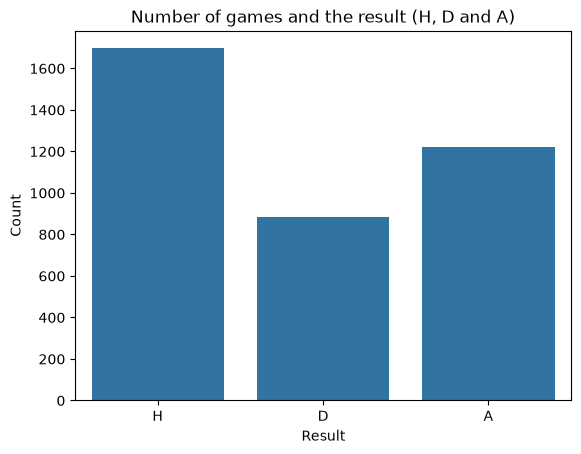

In [10]:
sns.countplot(x = 'FTR', data = df)                           #to check in a graph
plt.title('Number of games and the result (H, D and A)')
plt.xlabel('Result')
plt.ylabel('Count')
plt.show()

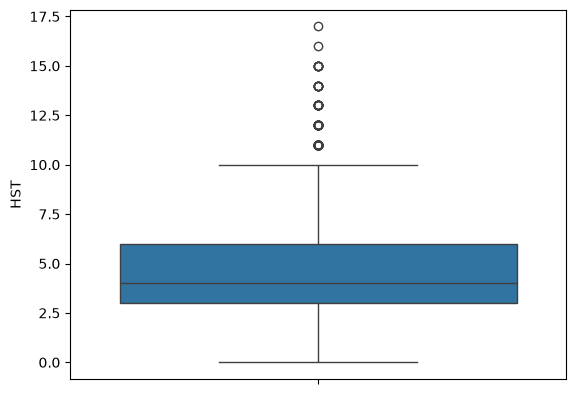

In [11]:
sns.boxplot(df['HST'])
plt.show()

In [12]:
#check outliers using IQR
Q1=df['HST'].quantile(0.25)     
Q3=df['HST'].quantile(0.75)     

IQR = Q3 - Q1                   
lower_bound = Q1 - 1.5 * IQR     
upper_bound = Q3 + 1.5 * IQR     

outliers = df[(df['HST'] < lower_bound) | (df['HST'] > upper_bound)]
print('lower bound:', lower_bound)
print('upper bound', upper_bound)
print ('number of outliers', len(outliers))

lower bound: -1.5
upper bound 10.5
number of outliers 110


- The boxplot shows that home teams that shot on target 11 or more times are outliers, but how it is a true result, it is not a fake match or a mistake of data, it will be kept in the analysis.

In [13]:
#For calculate correlation the result needs to be a number.
df['Result'] = df['FTR'].map({'A': 0, 'D': 1, 'H': 2})
print(df['Result'].value_counts())

Result
2    1696
0    1221
1     883
Name: count, dtype: int64


In [14]:
# Drop the column that I won't use, because these ones won't be used in the model (the goals show the match result) 
df_new = df.drop(['FTHG', 'FTAG', 'HTHG', 'HTAG'], axis = 1)

# axis = 1 means along columnwise

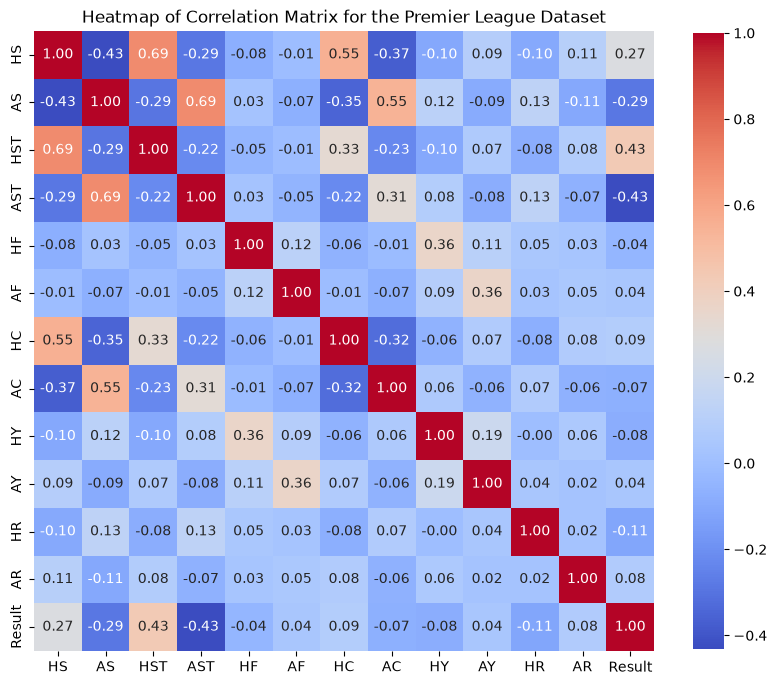

In [15]:
df_number = df_new.select_dtypes(include=['float64', 'int64'])

correlation_matrix = df_number.corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 10))

# Create a heatmap with the correlation matrix
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, cbar_kws={"shrink": .8})

# Set the title
plt.title('Heatmap of Correlation Matrix for the Premier League Dataset')

# Show the plot
plt.show()

- Analysing the heatmap, and to answer the question of the assessment (Which features most affect the results of a match?). There are the biggest correlations with the result of the matches, affecting the results in a strong way, are shots on target (AST and HST), followed by regular shots (HS and AS), while cards, corners and fouls don't have a very strong influence.
- The goals were excluded because the result of the match is decided by the goals. (The team that scores more goals wins), so these ones won't be used like a feature.

In [16]:
# don't use FTHG, FTAG, HTHG, HTAG, FTR - BECAUSE THE NUMBER OF GOALS SHOWS THE MATCH RESULT AND THE FTR IS THE RESULT ITSELF.

In [17]:
# Split dataset in features and target variable
feature_cols = ['HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']
X = df[feature_cols]               # Features of the dataset
y = df.Result                      # Target variable of the dataset

# Display the X and y arrays
print(X, y)

     HS  AS  HST  AST  HF  AF  HC  AC  HY  AY  HR  AR
0    19  10   10    3   7  10   6   7   1   2   0   0
1     3  16    3    3  13  11   3   6   1   1   1   0
2    10   7    4    2  16  15   4   3   3   3   0   0
3    10  12    5    4   8  10   5   7   0   1   0   0
4    16  14    6    4  14   8   6   5   0   0   0   0
..   ..  ..  ...  ...  ..  ..  ..  ..  ..  ..  ..  ..
375  25   9   10    3  13   8   3   3   0   1   0   0
376   9   6    2    1  16  10   3   6   2   0   0   0
377  14  14    6    3  12  10   4  10   2   4   0   0
378  12  16    2    5   8  10   7   4   1   1   0   0
379   6  15    3    9  12  10   4   5   1   0   0   0

[3800 rows x 12 columns] 0      2
1      1
2      1
3      2
4      2
      ..
375    2
376    2
377    0
378    2
379    0
Name: Result, Length: 3800, dtype: int64


# Modeling

The result of a match is AWAY, DRAW or Home, so it is a Classification and for that will be used the models Decision tree and Random forest, beeing a Decision Tree a easy way to understand, because it make questions of yers or not for each feature untill a final result and a Random forest a group of decisions trees.

In [18]:
# Split dataset into training and test - 5%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, random_state = 1) # 95% training and 5% test

X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape

((3800, 12), (3800,), (3610, 12), (190, 12), (3610,), (190,))

In [19]:
#Decision Tree
model = DecisionTreeClassifier(random_state = 42)   
model.fit(X_train, y_train)                         

y_pred = model.predict(X_test)                      # For Predict the result

print("Training Accuracy :", model.score(X_train, y_train))   # Accuracy training
print("Testing Accuracy :", model.score(X_test, y_test))      # Accuracy test

cm = confusion_matrix(y_test, y_pred)               # Compare real and predicted results
print(cm)
#AWAY, DRAW AND HOME RESULT

Training Accuracy : 1.0
Testing Accuracy : 0.4842105263157895
[[30  8 19]
 [13 15 17]
 [18 23 47]]


In [20]:
#Cross Validation - Decision Tree
cvs = cross_val_score(estimator = model, X = X_train, y = y_train, cv = 10) #Test the model 10 times crossing the data
print(cvs, "\n Mean Accuracy :", cvs.mean(), "\nStandard Deviation :", cvs.std())

[0.50692521 0.50692521 0.47091413 0.48476454 0.46814404 0.49861496
 0.55401662 0.52354571 0.47922438 0.47645429] 
 Mean Accuracy : 0.4969529085872576 
Standard Deviation : 0.025604919685964206


In [21]:
#Random Forest
model = RandomForestClassifier(random_state = 42)     
model.fit(X_train, y_train)                           

y_pred = model.predict(X_test)                        

print("Training Accuracy :", model.score(X_train, y_train))   # Accuracy of training 
print("Testing Accuracy :", model.score(X_test, y_test))      # Accuracy of test 

cm = confusion_matrix(y_test, y_pred)                 # Compare real and predicted results
print(cm)
#AWAY, DRAW AND HOME RESULT

Training Accuracy : 1.0
Testing Accuracy : 0.6157894736842106
[[45  2 10]
 [16  6 23]
 [12 10 66]]


In [22]:
# Cross validatio - random forest
cvs = cross_val_score(estimator = model, X = X_train, y = y_train, cv = 10) #Test the model 10 times crossing the data
print(cvs, "\n Mean Accuracy :", cvs.mean(), "\nStandard Deviation :", cvs.std())

[0.60941828 0.59279778 0.58725762 0.58448753 0.55955679 0.5734072
 0.61218837 0.59556787 0.57063712 0.60110803] 
 Mean Accuracy : 0.5886426592797784 
Standard Deviation : 0.016211495721218327


In [23]:
# Split dataset into training and test - 15%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = 1) # 85% training and 15% test

X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape

((3800, 12), (3800,), (3230, 12), (570, 12), (3230,), (570,))

In [24]:
#Decision Tree
model = DecisionTreeClassifier(random_state = 42)   
model.fit(X_train, y_train)                         

y_pred = model.predict(X_test)                      # For Predict the result

print("Training Accuracy :", model.score(X_train, y_train))   # Accuracy training
print("Testing Accuracy :", model.score(X_test, y_test))      # Accuracy test

cm = confusion_matrix(y_test, y_pred)               # Compare real and predicted results
print(cm)
#AWAY, DRAW AND HOME RESULT

Training Accuracy : 1.0
Testing Accuracy : 0.47368421052631576
[[ 89  46  38]
 [ 50  41  50]
 [ 43  73 140]]


In [25]:
#Cross Validation - Decision Tree
cvs = cross_val_score(estimator = model, X = X_train, y = y_train, cv = 10) #Test the model 10 times crossing the data
print(cvs, "\n Mean Accuracy :", cvs.mean(), "\nStandard Deviation :", cvs.std())

[0.55417957 0.46439628 0.47678019 0.49535604 0.51702786 0.50154799
 0.49845201 0.49226006 0.52321981 0.49845201] 
 Mean Accuracy : 0.5021671826625387 
Standard Deviation : 0.023691797485707728


In [26]:
#Random Forest
model = RandomForestClassifier(random_state = 42)     
model.fit(X_train, y_train)                           

y_pred = model.predict(X_test)                        

print("Training Accuracy :", model.score(X_train, y_train))   # Accuracy of training 
print("Testing Accuracy :", model.score(X_test, y_test))      # Accuracy of test 

cm = confusion_matrix(y_test, y_pred)                 # Compare real and predicted results
print(cm)
#AWAY, DRAW AND HOME RESULT

Training Accuracy : 1.0
Testing Accuracy : 0.5912280701754385
[[129   9  35]
 [ 51  17  73]
 [ 51  14 191]]


In [27]:
# Cross validatio - random forest
cvs = cross_val_score(estimator = model, X = X_train, y = y_train, cv = 10) #Test the model 10 times crossing the data
print(cvs, "\n Mean Accuracy :", cvs.mean(), "\nStandard Deviation :", cvs.std())

[0.6006192  0.64705882 0.54798762 0.58823529 0.58823529 0.57894737
 0.61919505 0.6130031  0.60681115 0.55727554] 
 Mean Accuracy : 0.5947368421052632 
Standard Deviation : 0.027879252668365894


In [28]:
# Split dataset into training and test - 25%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 1) # 75% training and 25% test

X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape

((3800, 12), (3800,), (2850, 12), (950, 12), (2850,), (950,))

In [29]:
#Decision Tree
model = DecisionTreeClassifier(random_state = 42)   
model.fit(X_train, y_train)                         

y_pred = model.predict(X_test)                      # For Predict the result

print("Training Accuracy :", model.score(X_train, y_train))   # Accuracy training
print("Testing Accuracy :", model.score(X_test, y_test))      # Accuracy test

cm = confusion_matrix(y_test, y_pred)               # Compare real and predicted results
print(cm)
#AWAY, DRAW AND HOME RESULT

Training Accuracy : 1.0
Testing Accuracy : 0.47157894736842104
[[146  79  74]
 [ 73  52  94]
 [ 79 103 250]]


In [30]:
#Cross Validation - Decision Tree
cvs = cross_val_score(estimator = model, X = X_train, y = y_train, cv = 10) #Test the model 10 times crossing the data
print(cvs, "\n Mean Accuracy :", cvs.mean(), "\nStandard Deviation :", cvs.std())

[0.45614035 0.45263158 0.51578947 0.47719298 0.45263158 0.50175439
 0.4877193  0.43859649 0.52280702 0.44210526] 
 Mean Accuracy : 0.4747368421052632 
Standard Deviation : 0.02931662413376044


In [31]:
#Random Forest
model = RandomForestClassifier(random_state = 42)     
model.fit(X_train, y_train)                           

y_pred = model.predict(X_test)                        

print("Training Accuracy :", model.score(X_train, y_train))   # Accuracy of training 
print("Testing Accuracy :", model.score(X_test, y_test))      # Accuracy of test 

cm = confusion_matrix(y_test, y_pred)                 # Compare real and predicted results
print(cm)
#AWAY, DRAW AND HOME RESULT

Training Accuracy : 1.0
Testing Accuracy : 0.6063157894736843
[[215  20  64]
 [ 76  32 111]
 [ 71  32 329]]


In [32]:
# Cross validatio - random forest
cvs = cross_val_score(estimator = model, X = X_train, y = y_train, cv = 10) #Test the model 10 times crossing the data
print(cvs, "\n Mean Accuracy :", cvs.mean(), "\nStandard Deviation :", cvs.std())

[0.62807018 0.54035088 0.58245614 0.56842105 0.61052632 0.58245614
 0.59649123 0.59649123 0.61052632 0.61052632] 
 Mean Accuracy : 0.5926315789473685 
Standard Deviation : 0.0240267625484491


---------------------------------------------------------------- TABLE RESULTS FOR 5%, 15% AND 25% --------------------------------------------------------------------
Test | Model | Training Accuracy | Testing Accuracy | Cross Validation Accuracy | 
|-|-|-|-|-|
| 5% | Decision Tree | 1.00 | 0.48 | 0.50 
| 5% | Random Forest | 1.00 | 0.62 | 0.59
| 15% | Decision Tree | 1.00 | 0.47 | 0.50
| 15%| Random Forest | 1.00 | 0.59 | 0.59
| 25% | Decision Tree | 1.00 | 0.47 | 0.47
| 25% | Random Forest | 1.00 | 0.61 | 0.59

- In every test, the training accuracy is 1.00 and the testing accuracy is very lower, because the trees are memorizing the data, this is evidence of overfitting, so it is necessary to introduce a limit to try to reduce it.
- Analysing the result is possible to understand that the random forest always works better than a decision tree.
- A model that predicts Home win always could predict 44.6%, so the random forest model is much better than just betting on the home team win.
- The sizes of the test (5%, 15% and 25%) almost don't change the accuracy.
- The biggest problem in predicting match results is predicting a Draw

# Hyperparameter
The main purpose of hyperparameter tuning in machine learning is try to find the proper configuration of the model to get the best results, how setting the max depth of the decision tree and the number of trees in the random forest. The GridSearchCV tests each value with cross validation in the training datas and checks which value is the best to use in the final model. It will be used in the last testing (25%) because this is the biggest size test and most reliable.

In [33]:
classifiers = {                                                        #Just using decision tree and random forest
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
} 

In [34]:
# Define hyperparameter grids for each classifier
param_grids = {
    "Decision Tree": {
        "max_depth": [None, 5, 10, 20, 30],            #Maximum depth of a tree

    },
    "Random Forest": {
        "n_estimators": [50, 100, 200],                #Number of trees in the forest
        "max_depth": [None, 5, 10, 20, 30],            #Maximum depth of each tree
        
    },
}

In [35]:
# Apply GridSearchCV for each classifier and evaluate performance metric scores
results = []
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv = 5, n_jobs = -1, verbose = 2)
    grid_search.fit(X_train, y_train)
    
    # Best model from grid search
    best_model = grid_search.best_estimator_
    
    # Predict on the test set with the best model
    y_pred = best_model.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score, grid_search.best_params_])

Running GridSearchCV for Decision Tree...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Running GridSearchCV for Random Forest...
Fitting 5 folds for each of 15 candidates, totalling 75 fits


In [36]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "Best Parameters"])
print("Model Performance Metrics on Test Set after GridSearchCV:")
print(results_df)

Model Performance Metrics on Test Set after GridSearchCV:
           Model  Accuracy  Precision    Recall  F1 Score  \
0  Decision Tree  0.575789   0.533942  0.575789  0.548475   
1  Random Forest  0.603158   0.555817  0.603158  0.556232   

                          Best Parameters  
0                        {'max_depth': 5}  
1  {'max_depth': 10, 'n_estimators': 200}  


The Best parameter for decision tree is max_depth 5 and the best parameters for random forest are max_depth 10 and n_estimators is 200 trees. The accuracy of the decision tree was between 0.47 and 0.48, but it went up to 0.58. The accuracy in the random forest didn't change so much, but the random forest is still working better than the decision tree.

# Evaluation

Building Decision Tree Model

In [39]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion = 'gini', max_depth = 5, random_state = 0)   #5 is the best value

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

In [41]:
# Combine into DataFrame
results = pd.DataFrame({
    "y_test (True)": y_test.reset_index(drop=True),  # reset index for alignment
    "y_pred (Predicted)": y_pred
})

# Show first 20 rows for a quick view
print(results.head(20))

# If you also want to check correctness
results["Correct?"] = results["y_test (True)"] == results["y_pred (Predicted)"]

print(results.head(20))

    y_test (True)  y_pred (Predicted)
0               2                   2
1               1                   0
2               0                   2
3               2                   2
4               2                   2
5               2                   2
6               0                   0
7               1                   2
8               2                   2
9               0                   0
10              1                   1
11              0                   1
12              0                   0
13              2                   2
14              1                   2
15              0                   0
16              1                   0
17              2                   2
18              2                   2
19              1                   0
    y_test (True)  y_pred (Predicted)  Correct?
0               2                   2      True
1               1                   0     False
2               0                   2     False
3         

It is noticeable, for example, that in these 20 matches, the total number of wrong predictions is 7 matches, but 5 of these mistakes are draws, which are the hardest to predict.

In [43]:
#Evaluating Model
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 0.5757894736842105
Accuracy: 0.58


In [45]:
X.columns.tolist() #features

['HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']

In [47]:
df['Result'].unique().tolist()

[2, 1, 0]

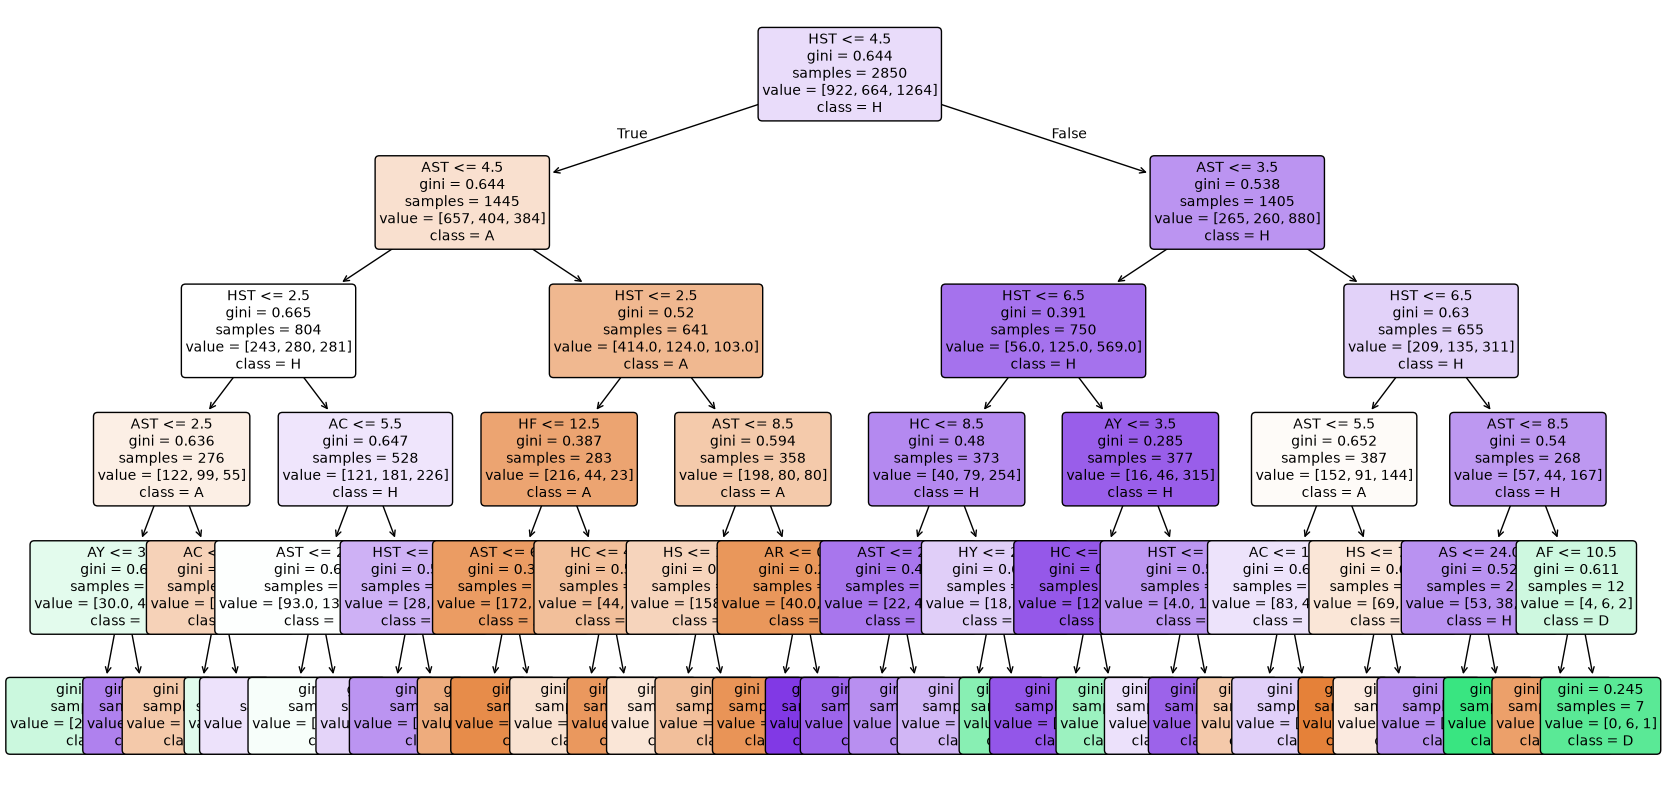

In [49]:
# Plot Decision Tree
plt.figure(figsize = (20, 10))
plot_tree(clf, filled = True, feature_names = X.columns.tolist(), class_names = ['A', 'D', 'H'], #classes of the model: 0 = A, 1 = D, 2 = H
          rounded = True, fontsize = 10)
plt.show()

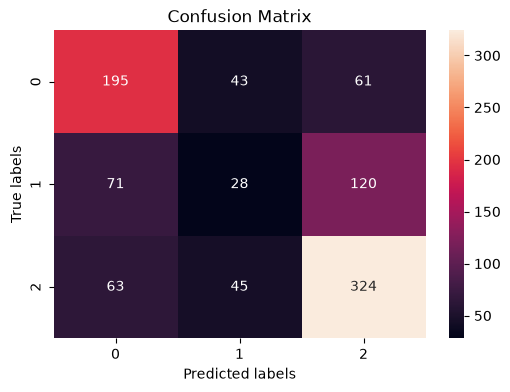

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.65      0.62       299
           1       0.24      0.13      0.17       219
           2       0.64      0.75      0.69       432

    accuracy                           0.58       950
   macro avg       0.49      0.51      0.49       950
weighted avg       0.53      0.58      0.55       950



In [52]:
# Predict by using an object classifier 'clf'
y_predict = clf.predict(X_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd')        #'d' for integer format
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

# Generate classification report - A / D / H
report = classification_report(y_test, y_predict)
print("Classification Report:")
print(report)

- In the tree the first question is about the home shots on target (HST), after that away shots on target (AST), followed by HST again. It shows how important shots on target are. Just like the Heatmap of Correlation Matrix showed before, shots and shots on Target are very important for predicting results.
- Analysing the result is much clear that predicting draws is much harder than predicting Away or Home results.

# Comparison of the models

In [56]:
depth = np.arange(1, 11)                      # max_depth values for test 1 to 10 (last does not count)
train_accuracy = np.zeros(len(depth))         # Declare and initialise the matrix (but using trees now)
test_accuracy = np.zeros(len(depth))          # Declare and initialise the matrix 

In [57]:
for i, k in enumerate(depth):                                      # for loop that checks the model for max_depth values 1, 2, 3, ..., 10
    dt = DecisionTreeClassifier(max_depth = k, random_state = 0)   # Initialise an object dt using DecisionTreeClassifier method

    # Fit the model
    dt.fit(X_train, y_train)                                       # Call fit method to implement the ML DecisionTreeClassifier model

    # Compute accuracy on the training set
    train_accuracy[i] = dt.score(X_train, y_train)                 # Save the score value in the train_accuracy array

    # Compute accuracy on the test set
    test_accuracy[i] = dt.score(X_test, y_test)                    # Save the score value in the test_accuracy array

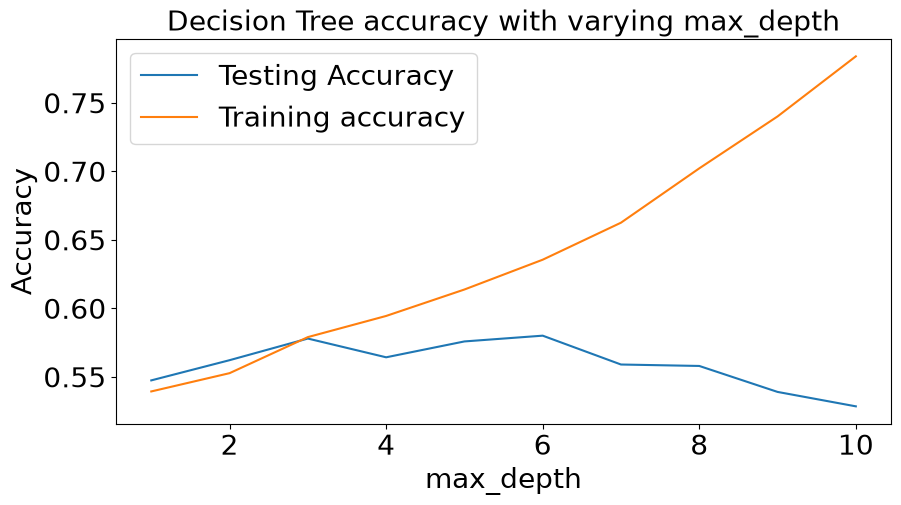

In [58]:
plt.figure(figsize = (10, 5))
plt.title('Decision Tree accuracy with varying max_depth', fontsize = 20)
plt.plot(depth, test_accuracy, label = 'Testing Accuracy')
plt.plot(depth, train_accuracy, label = 'Training accuracy')
plt.legend(prop={'size': 20})
plt.xlabel('max_depth', fontsize = 20)
plt.ylabel('Accuracy', fontsize = 20)
plt.xticks(fontsize = 20)
plt.yticks(fontsize = 20)
plt.show()

Looking at the graph seems like the max depth 6 could be a little better than max depth 5 in the testing accuracy, but can be checked that how bigger is the max depth, smaller is the testing accuracy, showing a possible overfitting starting, and in the test list I worked just with none, 5, 10, 20 and 30, there was not 6.

# Observations about overfitting, underfitting and generalisation
- Overfitting happens when a model memorizes the training matches, for example, a tree with no limit. So it works well in training, but when it is necessary to use it in testing, it fails. 
- Underfitting happens when a model is poor, for example, with a max depth of 1 or 2.
- Generalization happens when a model works the best possible with new data, in this case with a max depth between 3 and 6.
- In this assessment, the GridSearchCv chose max depth 5, increasing the accuracy in the decision tree.
- But the best model is Random Forest, and the hardest result to predict is Draws.